# Fundamentals of Convolutional Neural Networks — Convolution, Pooling and Dense Layers (PyTorch)


A typical CNN for classification has three kinds of layers, and we will go through them in order:

```
image ──► [ Conv → ReLU → Pool ] × N ──► Flatten ──► Dense ──► class scores
          └──── feature extractor ───┘              └── classifier ──┘
```

| Part | Topic | What you should be able to do afterwards |
|---|---|---|
| 1 | The convolution operation | Compute a convolution by hand and explain what a kernel does |
| 2 | Convolutional layers | Read the shapes and count the parameters of `nn.Conv2d` |
| 3 | Padding and stride | Predict the output size of any convolution |
| 4 | Pooling layers | Explain downsampling, receptive field, invariance vs. equivariance |
| 5 | Dense layers | Build the classification head and choose the right loss |
| 6 | MLP vs. CNN | Compare both on parameters, accuracy and robustness to shifts |

The notebook is self-contained: every figure is generated by the code below, the photographs ship with scikit-learn and Fashion-MNIST is downloaded by torchvision.

## 0. Setup

In [1]:
import math
import time

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.datasets import load_sample_images
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

torch.manual_seed(0)
np.random.seed(0)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch", torch.__version__, "| device:", device)

PyTorch 2.14.0 | device: cpu


In [2]:
# Small plotting helpers used throughout the notebook.

def show_images(images, titles=None, cmap="gray", figsize=None, suptitle=None):
    # Show a list of 2-D (grayscale) or H x W x 3 (RGB) arrays side by side.
    n = len(images)
    fig, axes = plt.subplots(1, n, figsize=figsize or (4 * n, 4))
    axes = np.atleast_1d(axes)
    for ax, img, title in zip(axes, images, titles or [None] * n):
        ax.imshow(torch.as_tensor(img).detach().cpu().numpy(), cmap=cmap)
        ax.set_title(title, fontsize=10)
        ax.axis("off")
    if suptitle:
        fig.suptitle(suptitle)
    plt.tight_layout()
    plt.show()


def show_matrix(ax, M, title=None, highlight=None, cmap="Blues", fmt="{:.0f}", fontsize=11):
    # Draw a small matrix with its values written in the cells.
    # highlight = (row, col, height, width) draws a red box around a patch.
    M = torch.as_tensor(M).detach().float().numpy()
    vmax = max(float(np.abs(M).max()), 1e-9)
    signed = cmap == "coolwarm"                 # diverging colours: 0 is always the neutral grey
    ax.imshow(M, cmap=cmap, vmin=-vmax if signed else 0, vmax=vmax, alpha=0.75)
    for (i, j), v in np.ndenumerate(M):
        ax.text(j, i, fmt.format(v), ha="center", va="center", fontsize=fontsize)
    ax.set_xticks(np.arange(-0.5, M.shape[1]), minor=True)
    ax.set_yticks(np.arange(-0.5, M.shape[0]), minor=True)
    ax.grid(which="minor", color="white", linewidth=2)
    ax.tick_params(which="both", bottom=False, left=False, labelbottom=False, labelleft=False)
    if highlight is not None:
        r, c, h, w = highlight
        ax.add_patch(plt.Rectangle((c - 0.5, r - 0.5), w, h, fill=False, edgecolor="crimson", linewidth=3.5,
                                   zorder=5, clip_on=False))
    ax.set_title(title, fontsize=10)

## 1. The convolution operation

Mathematically, convolution is an operation between two functions $f$ and $g$ in which one of them is flipped and slid over the other; the result $f * g$ measures how much they overlap at every shift. It appears in differential equations, probability and signal processing. Two good introductions: [But what is a convolution?](https://www.youtube.com/watch?v=KuXjwB4LzSA) and [The Convolution of Two Functions](https://www.youtube.com/watch?v=AgKQQtEc9dk).

In image processing the two "functions" are an **image** $X$ and a small matrix of weights called a **kernel** (or filter) $W$. We slide the kernel over the image and, at every position, take the weighted sum of the pixels under it:

$$
Y(i,j) \;=\; \sum_{u=0}^{k_h-1}\;\sum_{v=0}^{k_w-1} W(u,v)\; X(i+u,\; j+v)
$$

where the kernel has size $k_h \times k_w$. Each output value is the dot product between the kernel and one patch of the image.

> **A note on terminology.** Strictly speaking, the formula above is **cross-correlation**. True convolution flips the kernel first: $X(i-u, j-v)$. Deep learning libraries (PyTorch, TensorFlow, JAX) all implement cross-correlation and call it "convolution". For a CNN the difference is irrelevant, because the kernel is *learned*: the network would simply learn the flipped version. We follow the deep learning convention in this notebook.

Let's compute one by hand on a tiny example before touching any image.

patch * kernel summed = 1  ->  Y[1,2] = 1


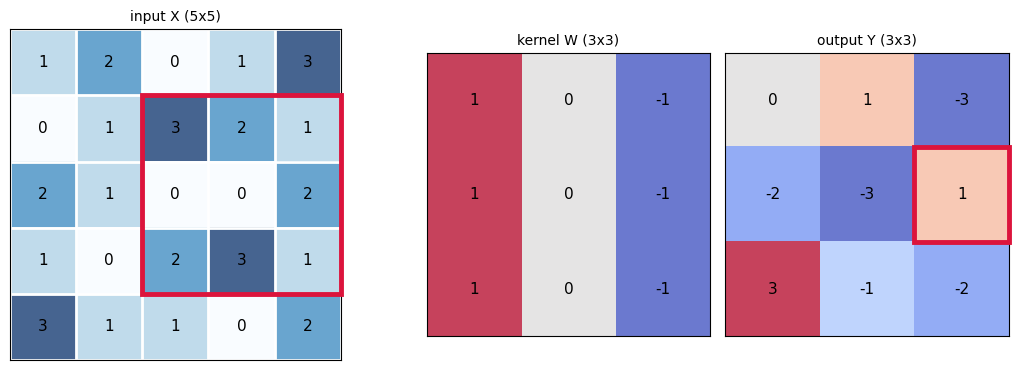

In [3]:
X = torch.tensor([[1, 2, 0, 1, 3],
                  [0, 1, 3, 2, 1],
                  [2, 1, 0, 0, 2],
                  [1, 0, 2, 3, 1],
                  [3, 1, 1, 0, 2]], dtype=torch.float32)

K = torch.tensor([[1, 0, -1],
                  [1, 0, -1],
                  [1, 0, -1]], dtype=torch.float32)

# F.conv2d expects input (N, C, H, W) and weight (out_channels, in_channels, kH, kW)
Y = F.conv2d(X[None, None], K[None, None])[0, 0]

i, j = 1, 2                                   # output position we want to explain
patch = X[i:i + 3, j:j + 3]
print(f"patch * kernel summed = {(patch * K).sum().item():.0f}  ->  Y[{i},{j}] = {Y[i, j].item():.0f}")

fig, axes = plt.subplots(1, 3, figsize=(11, 3.8), gridspec_kw={"width_ratios": [5, 3, 3]})
show_matrix(axes[0], X, "input X (5x5)", highlight=(i, j, 3, 3))
show_matrix(axes[1], K, "kernel W (3x3)", cmap="coolwarm")
show_matrix(axes[2], Y, "output Y (3x3)", highlight=(i, j, 1, 1), cmap="coolwarm")
plt.tight_layout()
plt.show()

The red patch of the input, multiplied element by element with the kernel and summed, gives the red cell of the output. Sliding the patch over all 9 valid positions fills the 3×3 output.

### 1.1 Writing it ourselves

The operation is short enough to implement with two `for` loops. It is slow, but it makes explicit what the library does for us.

In [7]:
def conv2d_naive(image, kernel, stride=1, padding=0):
    # Cross-correlation of a 2-D image with a 2-D kernel (what DL libraries call convolution).
    if padding > 0:
        image = F.pad(image, (padding, padding, padding, padding))   # zeros on the four sides
    H, W = image.shape
    kh, kw = kernel.shape
    out_h = (H - kh) // stride + 1
    out_w = (W - kw) // stride + 1
    out = torch.zeros(out_h, out_w, dtype=image.dtype)
    for i in range(out_h):
        for j in range(out_w):
            patch = image[i * stride:i * stride + kh, j * stride:j * stride + kw]
            out[i, j] = (patch * kernel).sum()
    return out


print(torch.equal(conv2d_naive(X, K), Y))    # same result as F.conv2d on the toy example

True


Now a real image. scikit-learn ships two photographs; we convert them to a float tensor in $[0, 1]$ and downsample them by 2 so the naive loops stay fast.

as loaded     : (2, 427, 640, 3) uint8
PyTorch tensor: (2, 3, 213, 320) torch.float32


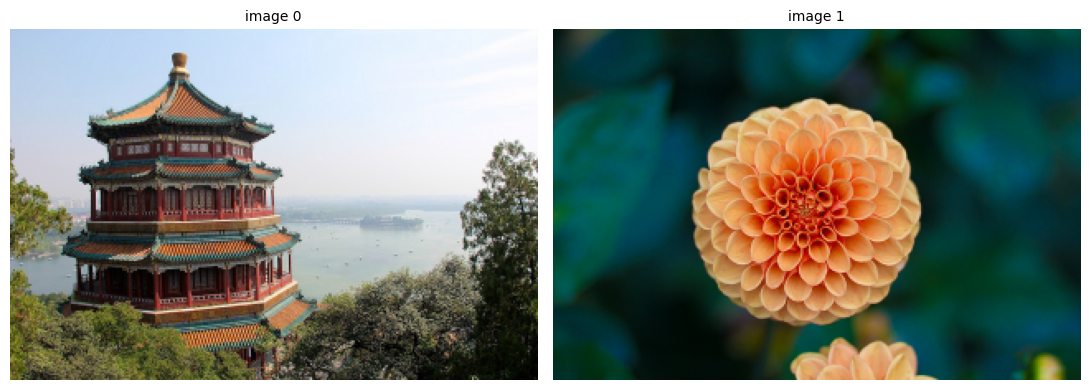

In [5]:
photos = np.stack(load_sample_images().images)            # (2, 427, 640, 3), uint8, channels LAST
print("as loaded     :", photos.shape, photos.dtype)

images = torch.from_numpy(photos).permute(0, 3, 1, 2)     # -> (N, C, H, W), channels FIRST
images = images.float() / 255.0                           # uint8 [0, 255] -> float [0, 1]
images = F.avg_pool2d(images, 2)                          # halve the resolution
print("PyTorch tensor:", tuple(images.shape), images.dtype)

gray = images.mean(dim=1)                                 # (N, H, W) simple grayscale version
show_images([images[0].permute(1, 2, 0), images[1].permute(1, 2, 0)], ["image 0", "image 1"], figsize=(11, 4))

> **Shape convention.** PyTorch uses **channels first**: `(N, C, H, W)` = batch, channels, height, width. Keras/TensorFlow and matplotlib use channels last `(N, H, W, C)`. That is why we call `.permute(...)` when moving between a tensor and a plot. Shape mismatches are the most common source of bugs when porting code from one framework to the other.

Let's apply an edge-detection kernel. Its weights sum to zero, so flat regions give 0 and only places where a pixel differs from its neighbours give a strong response.

naive loops:    398.6 ms
F.conv2d   :      0.4 ms
same result: True


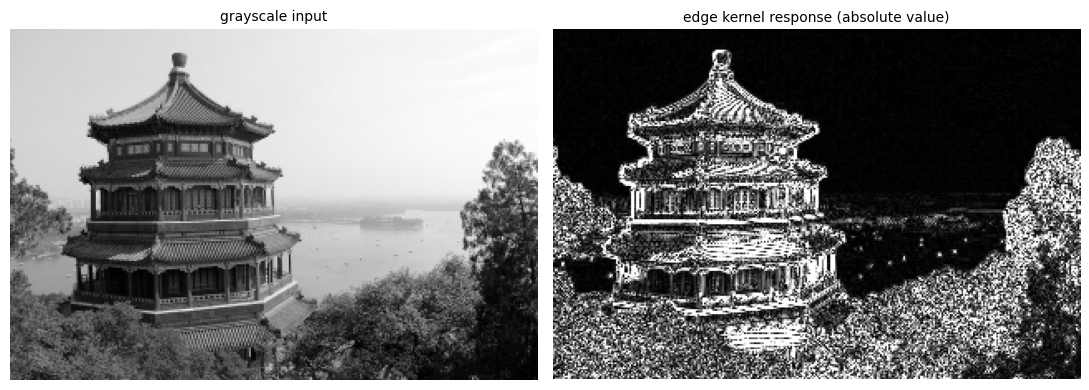

In [8]:
edge_kernel = torch.tensor([[-1., -1., -1.],
                            [-1.,  8., -1.],
                            [-1., -1., -1.]])

t0 = time.perf_counter()
edges_naive = conv2d_naive(gray[0], edge_kernel)
t_naive = time.perf_counter() - t0

t0 = time.perf_counter()
edges_torch = F.conv2d(gray[0][None, None], edge_kernel[None, None])[0, 0]
t_torch = time.perf_counter() - t0

print(f"naive loops: {t_naive * 1e3:8.1f} ms")
print(f"F.conv2d   : {t_torch * 1e3:8.1f} ms")
print("same result:", torch.allclose(edges_naive, edges_torch, atol=1e-5))

show_images([gray[0], edges_naive.abs().clamp(0, 1)], ["grayscale input", "edge kernel response (absolute value)"], figsize=(11, 4))

Both implementations agree, and the library version is orders of magnitude faster because it is vectorised.

Different kernels extract different information. Before deep learning, people designed these kernels by hand:

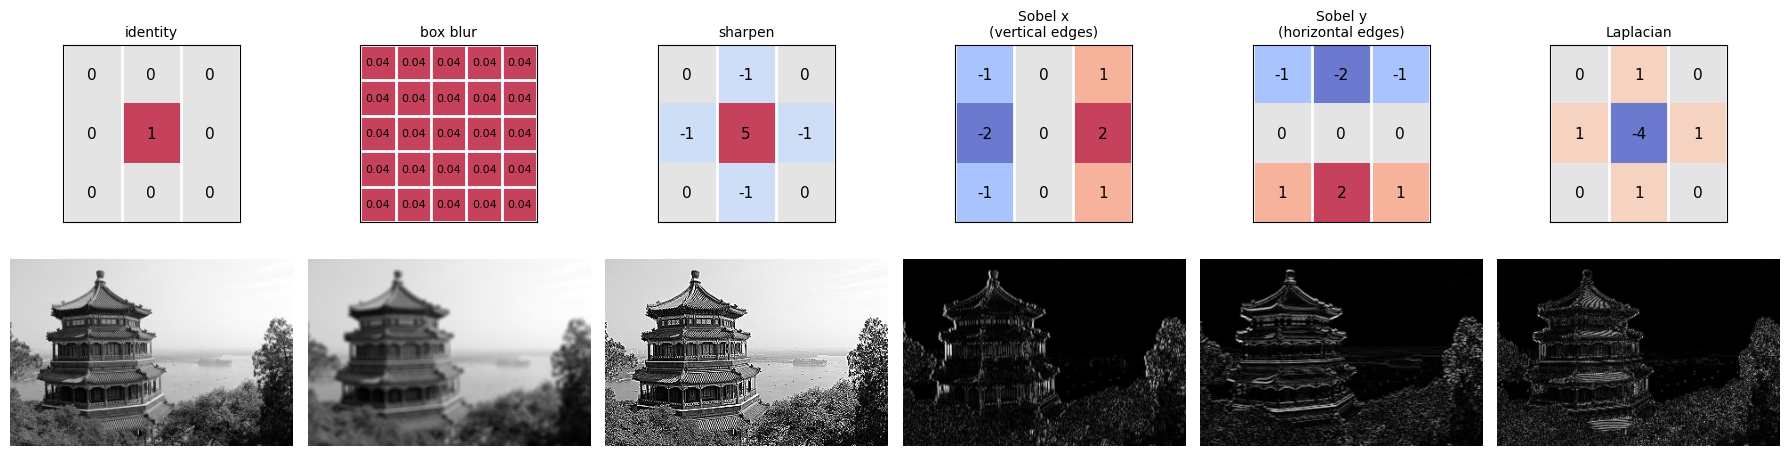

In [9]:
kernels = {
    "identity":   torch.tensor([[0., 0., 0.], [0., 1., 0.], [0., 0., 0.]]),
    "box blur":   torch.ones(5, 5) / 25,
    "sharpen":    torch.tensor([[0., -1., 0.], [-1., 5., -1.], [0., -1., 0.]]),
    "Sobel x\n(vertical edges)":   torch.tensor([[-1., 0., 1.], [-2., 0., 2.], [-1., 0., 1.]]),
    "Sobel y\n(horizontal edges)": torch.tensor([[-1., -2., -1.], [0., 0., 0.], [1., 2., 1.]]),
    "Laplacian":  torch.tensor([[0., 1., 0.], [1., -4., 1.], [0., 1., 0.]]),
}

fig, axes = plt.subplots(2, len(kernels), figsize=(18, 5.5), gridspec_kw={"height_ratios": [1, 2]})
for col, (name, k) in enumerate(kernels.items()):
    out = F.conv2d(gray[0][None, None], k[None, None])[0, 0]
    show_matrix(axes[0, col], k, name, cmap="coolwarm", fmt="{:.2g}", fontsize=8 if k.shape[0] > 3 else 11)
    signed = k.min() < 0 and abs(k.sum().item()) < 1e-6          # zero-sum kernels give signed outputs
    axes[1, col].imshow(out.abs() if signed else out.clamp(0, 1), cmap="gray")
    axes[1, col].axis("off")
plt.tight_layout()
plt.show()

**The key idea of a CNN:** instead of designing these kernels by hand, we let the network *learn* the kernel values with gradient descent, choosing whatever filters are most useful for the task.

One more observation: the output is slightly smaller than the input.

In [10]:
print("input :", tuple(gray[0].shape))
print("output:", tuple(edges_torch.shape))

input : (213, 320)
output: (211, 318)


A 3×3 kernel can only be placed at $H-2$ vertical and $W-2$ horizontal positions, so we lose a 1-pixel border on every side. We will fix this with **padding** in Part 3.

## 2. Convolutional layers

A convolutional layer is a set of kernels whose weights are **learnable**. Every kernel is slid over the input and produces one **feature map**: a spatial map telling *where* in the image that kernel's pattern was found.

It helps to view it as a layer of neurons with two restrictions compared to a dense layer:

1. **Local connectivity.** Each neuron is connected only to a small region of the input, called its **receptive field**, instead of to every pixel.
2. **Weight sharing.** All neurons of the same feature map use the *same* kernel and bias. This is exactly the sliding window: the same weights applied at every position.

For a single-channel input, the neuron at position $(i,j)$ computes

$$
z_{i,j} = \sum_{u,v} w_{u,v}\, x_{i+u,\,j+v} + b, \qquad a_{i,j} = \mathrm{ReLU}(z_{i,j})
$$

that is: dot product between the kernel and the patch in its receptive field, plus a bias, followed by a non-linearity.

These two restrictions are the **inductive biases** of CNNs, the assumptions about images that are built into the architecture:

- **Locality:** nearby pixels are more related than distant ones, so useful patterns (edges, corners, textures) are local.
- **Translation equivariance:** a pattern is the same pattern wherever it appears. Because the kernel is shared, a filter that detects an edge in the top-left corner detects it in the bottom-right corner too. A dense layer would have to learn it again for every position. This makes CNNs much more data-efficient on images ([Chollet, 2021](https://www.manning.com/books/deep-learning-with-python-second-edition)).
- **Hierarchy:** stacking layers composes features. The first layers learn edges and colour blobs, the next ones combine them into textures and parts, and the deepest ones into objects.

> **Equivariance is not invariance.** The original notebook described convolution as "translation-invariant". The precise term is **equivariant**: if the input shifts, the feature map *shifts by the same amount* (the output changes, in a predictable way). **Invariant** means the output *does not change at all*. Convolution gives equivariance; pooling and the final classifier add (approximate) invariance, as we will see in Part 4.

We can verify the equivariance numerically: convolving a shifted image gives the shifted feature map.

In [9]:
# conv(shift(x)) == shift(conv(x))
# Circular padding + torch.roll make the equality exact, including at the borders.
conv = nn.Conv2d(1, 1, kernel_size=3, padding=1, padding_mode="circular", bias=False)
shift = (15, 40)                                           # pixels down, pixels right

x = gray[0][None, None]
with torch.no_grad():
    shift_then_conv = conv(torch.roll(x, shift, dims=(2, 3)))
    conv_then_shift = torch.roll(conv(x), shift, dims=(2, 3))

print("conv(shift(x)) == shift(conv(x)):", torch.allclose(shift_then_conv, conv_then_shift, atol=1e-6))

conv(shift(x)) == shift(conv(x)): True


### 2.1 Why do we need the non-linearity?

Convolution is a **linear** operation, and composing linear operations gives another linear operation. Two stacked 3×3 convolutions without an activation in between are exactly equivalent to a single 5×5 convolution, so depth would add nothing. The activation function (ReLU here) is what lets stacked layers represent increasingly complex functions.

In [10]:
k1, k2 = torch.randn(1, 1, 3, 3), torch.randn(1, 1, 3, 3)

two_linear_layers = F.conv2d(F.conv2d(x, k1), k2)

# The equivalent single kernel is k1 convolved with k2 (flip because F.conv2d is a cross-correlation)
k_equivalent = F.conv2d(k1, k2.flip(2, 3), padding=2)
one_layer = F.conv2d(x, k_equivalent)

print("equivalent kernel shape:", tuple(k_equivalent.shape[2:]))
print("two 3x3 convs == one 5x5 conv:", torch.allclose(two_linear_layers, one_layer, atol=1e-4))

with_relu = F.conv2d(F.relu(F.conv2d(x, k1)), k2)
print("still true with a ReLU in between:", torch.allclose(with_relu, one_layer, atol=1e-4))

equivalent kernel shape: (5, 5)
two 3x3 convs == one 5x5 conv: True
still true with a ReLU in between: False


### 2.2 Convolution on multiple channels

So far the input had one channel. A colour image has three (R, G, B), and the feature maps inside a network have dozens or hundreds.

With $C_{in}$ input channels, a **filter** is a stack of $C_{in}$ kernels, one per input channel, i.e. a 3-D block of shape $C_{in} \times k_h \times k_w$. Each kernel is slid over its own channel, the $C_{in}$ results are **added together**, and a single bias is added. The result is **one** feature map per filter:

$$
z_{i,j} = \sum_{c=1}^{C_{in}} \;\sum_{u,v} w_{c,u,v}\; x_{c,\,i+u,\,j+v} \;+\; b
$$

Terminology: a *kernel* is one 2-D slice; a *filter* is the whole 3-D stack. For a grayscale input they coincide.

A layer has $C_{out}$ such filters, each with its own weights, so it outputs $C_{out}$ feature maps. Summary of shapes:

| Tensor | Shape |
|---|---|
| input | $(N,\; C_{in},\; H,\; W)$ |
| weight | $(C_{out},\; C_{in},\; k_h,\; k_w)$ |
| bias | $(C_{out})$ |
| output | $(N,\; C_{out},\; H_{out},\; W_{out})$ |

Let's check the "one kernel per channel, then add" description against PyTorch.

same result: True


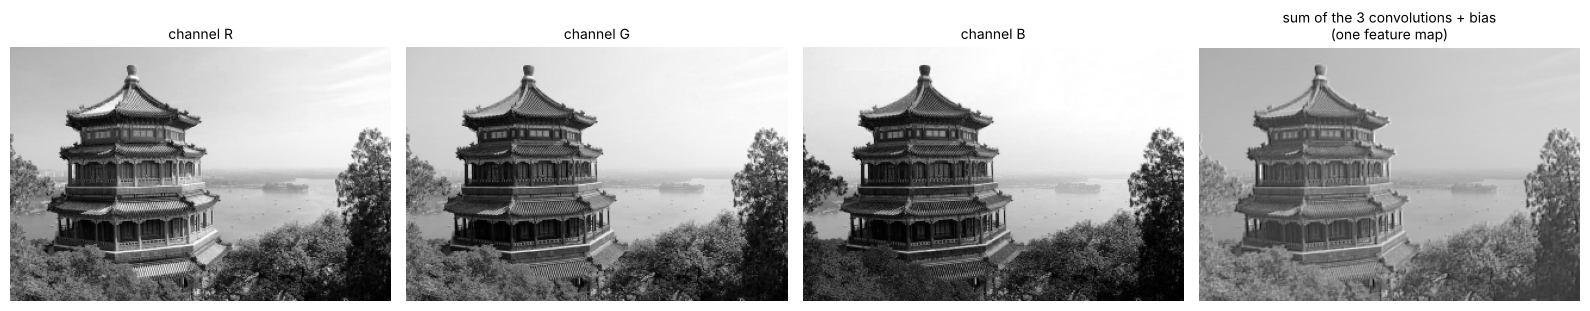

In [11]:
rgb = images[0]                              # (3, H, W)
filt = torch.randn(3, 3, 3)                  # one filter = 3 kernels of 3x3 (one per input channel)
bias = torch.randn(1)

# By hand: convolve each channel with its own kernel, add the three results, add the bias
per_channel = [F.conv2d(rgb[c][None, None], filt[c][None, None])[0, 0] for c in range(3)]
manual = per_channel[0] + per_channel[1] + per_channel[2] + bias

# PyTorch: weight of shape (out_channels=1, in_channels=3, 3, 3)
library = F.conv2d(rgb[None], filt[None], bias=bias)[0, 0]

print("same result:", torch.allclose(manual, library, atol=1e-5))

show_images([rgb[0], rgb[1], rgb[2], manual],
            ["channel R", "channel G", "channel B", "sum of the 3 convolutions + bias\n(one feature map)"],
            figsize=(16, 3.2))

### 2.3 `nn.Conv2d` in practice

The main arguments of [`nn.Conv2d`](https://pytorch.org/docs/stable/generated/torch.nn.Conv2d.html):

1. **`in_channels`**: channels of the input (3 for RGB). Unlike Keras, PyTorch needs it explicitly.
2. **`out_channels`**: number of filters = number of feature maps produced (`filters` in Keras).
3. **`kernel_size`**: `3` means a 3×3 kernel.

Let's create a layer with 4 filters and pass our batch of two images through it.

In [12]:
torch.manual_seed(0)
conv_layer = nn.Conv2d(in_channels=3, out_channels=4, kernel_size=3)

with torch.no_grad():                        # we are only inspecting, no gradients needed
    feature_maps = conv_layer(images)

print("input :", tuple(images.shape))
print("output:", tuple(feature_maps.shape))

input : (2, 3, 213, 320)
output: (2, 4, 211, 318)


The channel axis now holds the 4 feature maps (and height and width shrank by 2, as before). The weights are still random, so each map is just a random linear mixture of the colour channels and their neighbours:

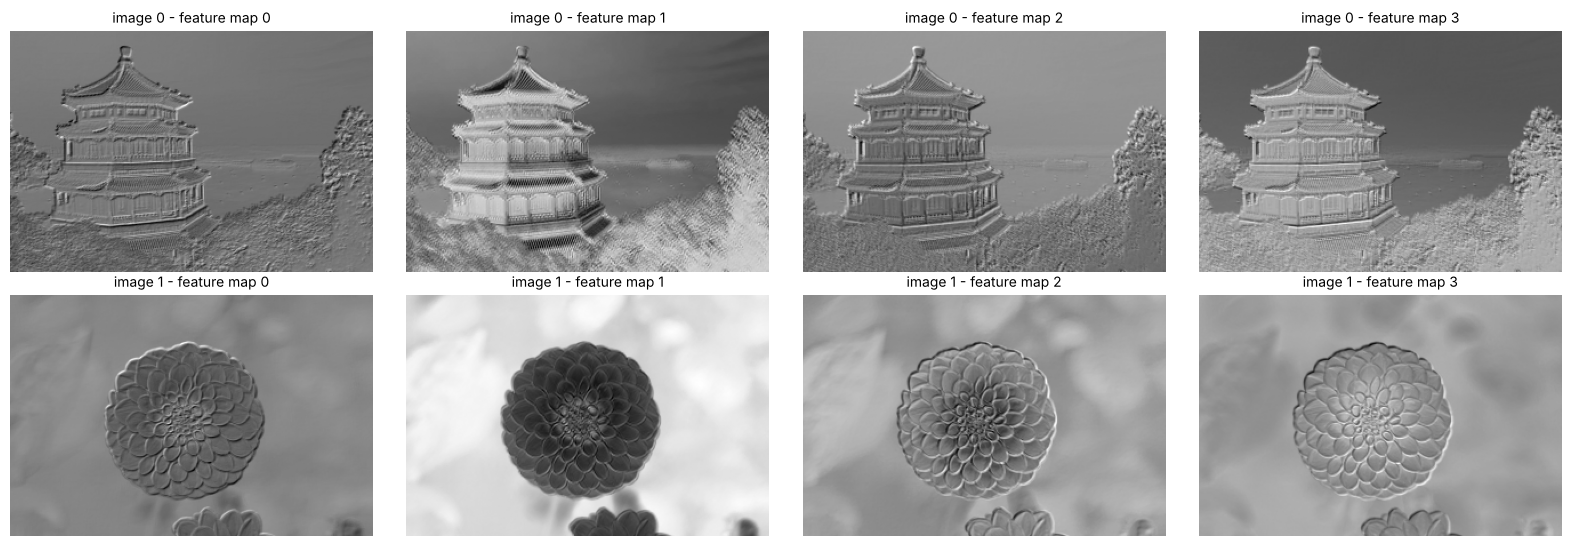

In [13]:
fig, axes = plt.subplots(2, 4, figsize=(16, 5.5))
for n in range(2):
    for f in range(4):
        axes[n, f].imshow(feature_maps[n, f], cmap="gray")
        axes[n, f].set_title(f"image {n} - feature map {f}", fontsize=10)
        axes[n, f].axis("off")
plt.tight_layout()
plt.show()

Now the parameters of the layer:

In [14]:
print("weight:", tuple(conv_layer.weight.shape), " (out_channels, in_channels, kH, kW)")
print("bias  :", tuple(conv_layer.bias.shape))

n_params = sum(p.numel() for p in conv_layer.parameters())
print("parameters:", n_params, "=", "(3*3*3 + 1) * 4")

weight: (4, 3, 3, 3)  (out_channels, in_channels, kH, kW)
bias  : (4,)
parameters: 112 = (3*3*3 + 1) * 4


The number of parameters of a convolutional layer is

$$
\#\text{params} = (k_h \cdot k_w \cdot C_{in} + 1)\cdot C_{out}
$$

Note what is **missing** from the formula: the height and width of the image. A convolutional layer has the same number of parameters for a 32×32 image as for a 4000×3000 one. This is the consequence of weight sharing and the main reason CNNs scale to images where dense layers cannot.

Let's reproduce the first feature map with our own function, using the weights of the layer: three kernels (one per channel), summed, plus the bias.

In [15]:
w = conv_layer.weight.detach()               # (4, 3, 3, 3)
b = conv_layer.bias.detach()                 # (4,)

manual_fm = sum(conv2d_naive(images[0, c], w[0, c]) for c in range(3)) + b[0]

print("exactly equal  (torch.equal)   :", torch.equal(manual_fm, feature_maps[0, 0]))
print("numerically equal (allclose)   :", torch.allclose(manual_fm, feature_maps[0, 0], atol=1e-5))
print("largest absolute difference    :", (manual_fm - feature_maps[0, 0]).abs().max().item())

exactly equal  (torch.equal)   : False
numerically equal (allclose)   : True
largest absolute difference    : 2.8312206268310547e-07


> **Why not *exactly* equal?** Both computations are mathematically identical, but floating-point addition is not associative: summing the same numbers in a different order gives results that differ in the last bits (around $10^{-7}$ in `float32`). Our loops and the optimised library routine add the terms in different orders. This is why you should compare floating-point tensors with `torch.allclose`, never with `==` or `torch.equal`. (In the original TensorFlow notebook the mismatch was larger for a different reason: the manual version was run on the raw 0–255 image and the layer on the image rescaled to 0–1.)

**Setting the weights ourselves.** Keras uses `kernel_initializer`; in PyTorch we simply write into `layer.weight` inside `torch.no_grad()`. Here we load the Sobel kernels from Part 1 into a layer:

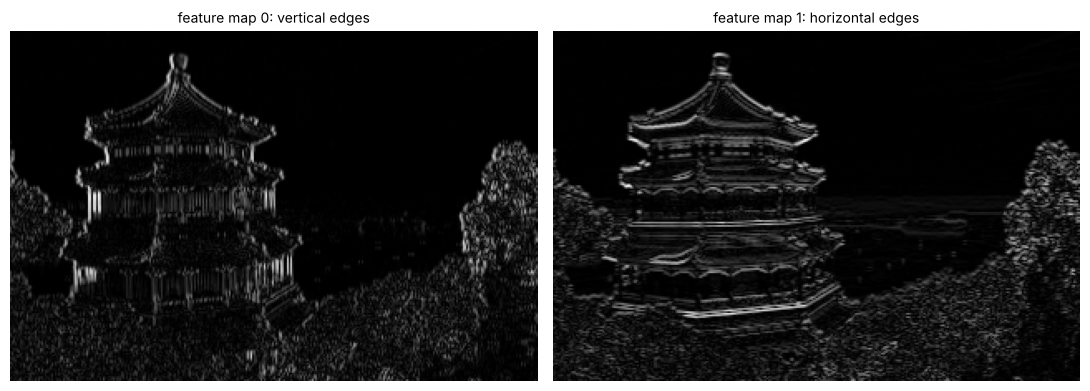

In [16]:
sobel_layer = nn.Conv2d(in_channels=1, out_channels=2, kernel_size=3, bias=False)

with torch.no_grad():
    sobel_layer.weight[0, 0] = kernels["Sobel x\n(vertical edges)"]
    sobel_layer.weight[1, 0] = kernels["Sobel y\n(horizontal edges)"]
    out = sobel_layer(gray[0][None, None])[0]

show_images([out[0].abs(), out[1].abs()], ["feature map 0: vertical edges", "feature map 1: horizontal edges"], figsize=(11, 4))

By default `nn.Conv2d` initialises its weights with a Kaiming-uniform scheme (Keras uses Glorot uniform). You can change it with the functions in [`torch.nn.init`](https://pytorch.org/docs/stable/nn.init.html), for example `nn.init.kaiming_normal_(layer.weight, nonlinearity="relu")`.

`nn.Conv2d(...)` is the *layer* (it owns the weights); `F.conv2d(input, weight, bias)` is the underlying *function*, to which you pass the weights yourself. This is the same relation as `tf.keras.layers.Conv2D` and `tf.nn.conv2d`.

## 3. Padding and stride

### 3.1 Padding

We saw twice that the output of a convolution is smaller than its input. With a $k \times k$ kernel there are only $n - k + 1$ positions per axis where the kernel fits. This has two costs:

1. **Shrinking.** Every layer removes $k-1$ pixels per axis, which limits how many layers we can stack.
2. **Border information is under-used.** A corner pixel is covered by the kernel only once, while a central pixel is covered $k^2$ times.

The solution is to **pad** the input with a border of extra pixels (usually zeros) before convolving. Three classic settings for a kernel of size $k$ and stride 1:

| Name | Padding $p$ | Output size | Meaning |
|---|---|---|---|
| **valid** | $0$ | $n - k + 1$ | no padding, only complete overlaps |
| **same** (half) | $(k-1)/2$ | $n$ | output has the same size as the input |
| **full** | $k - 1$ | $n + k - 1$ | every partial overlap is used |

(For "same" padding $k$ should be odd, which is one reason 3×3, 5×5 and 7×7 kernels are the standard choices.)

The figure counts how many kernel positions touch each pixel of an 8×8 input.

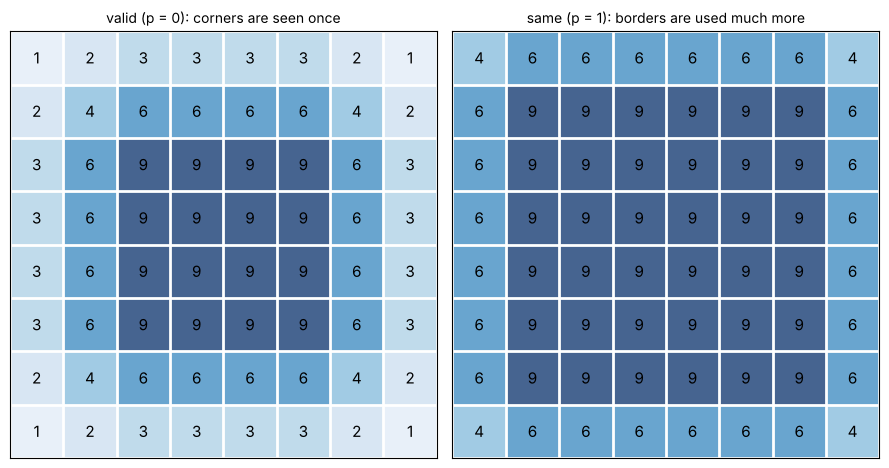

In [17]:
def coverage(n=8, k=3, padding=0):
    # How many kernel positions cover each pixel of an n x n input.
    # conv_transpose2d with a kernel of ones "paints" every position where the kernel was placed
    out_size = n + 2 * padding - k + 1
    painted = F.conv_transpose2d(torch.ones(1, 1, out_size, out_size), torch.ones(1, 1, k, k))
    return painted[0, 0, padding:padding + n, padding:padding + n]


fig, axes = plt.subplots(1, 2, figsize=(9, 4.6))
show_matrix(axes[0], coverage(padding=0), "valid (p = 0): corners are seen once")
show_matrix(axes[1], coverage(padding=1), "same (p = 1): borders are used much more")
plt.tight_layout()
plt.show()

In PyTorch, `padding` accepts an integer (pixels added on each side) or the strings `"valid"` and `"same"`. The default is `padding=0`, i.e. valid.

In [18]:
print("input                  :", tuple(images.shape))

for name, pad in [("valid", "valid"), ("same", "same"), ("same, as integer p=1", 1), ("full, p=2", 2)]:
    layer = nn.Conv2d(3, 4, kernel_size=3, padding=pad)
    print(f"{name:23s}:", tuple(layer(images).shape))

input                  : (2, 3, 213, 320)
valid                  : (2, 4, 211, 318)
same                   : (2, 4, 213, 320)
same, as integer p=1   : (2, 4, 213, 320)
full, p=2              : (2, 4, 215, 322)


With "same" padding the spatial size is preserved (the channel axis still changes from 3 to 4 feature maps). "Full" padding makes the output larger than the input; in Keras it requires a separate `ZeroPadding2D` layer, in PyTorch it is just `padding=k-1`.

Zeros are not the only option: `padding_mode` can be `"zeros"` (default), `"reflect"`, `"replicate"` or `"circular"`. Reflect padding is common in image-to-image models (denoising, enhancement, style transfer), where a black border would create artefacts at the edges.

### 3.2 Stride

The **stride** $s$ is the step of the kernel as it moves over the image. So far we used $s = 1$. With $s = 2$ the kernel jumps two pixels at a time and the output has about half the size:

$$
Y(i,j) = \sum_{u,v} W(u,v)\; X(s\,i+u,\; s\,j+v)
$$

A stride larger than 1 is a way of **downsampling**: fewer positions to compute (less memory and time), and the layers that follow see a larger portion of the original image.

### 3.3 The output-size formula

Padding and stride together give the formula you will use constantly when designing networks:

$$
\boxed{\,n_{out} = \left\lfloor \frac{n_{in} + 2p - k}{s} \right\rfloor + 1\,}
$$

applied independently to height and width ($\lfloor\cdot\rfloor$ is rounding down). Let's write it and check it against PyTorch.

In [19]:
def conv_out_size(n, k, s=1, p=0):
    return (n + 2 * p - k) // s + 1


H, W = images.shape[2:]
print(f"input: {H} x {W}\n")
print(f"{'k':>2} {'s':>2} {'p':>2} | {'formula':>11} | {'PyTorch':>11}")
for k, s, p in [(3, 1, 0), (3, 1, 1), (5, 1, 2), (3, 2, 1), (7, 2, 3), (3, 3, 0)]:
    layer = nn.Conv2d(3, 4, kernel_size=k, stride=s, padding=p)
    out = layer(images)
    formula = f"{conv_out_size(H, k, s, p)} x {conv_out_size(W, k, s, p)}"
    actual = f"{out.shape[2]} x {out.shape[3]}"
    print(f"{k:>2} {s:>2} {p:>2} | {formula:>11} | {actual:>11}")

input: 213 x 320

 k  s  p |     formula |     PyTorch
 3  1  0 |   211 x 318 |   211 x 318
 3  1  1 |   213 x 320 |   213 x 320
 5  1  2 |   213 x 320 |   213 x 320
 3  2  1 |   107 x 160 |   107 x 160
 7  2  3 |   107 x 160 |   107 x 160
 3  3  0 |    71 x 106 |    71 x 106


input : (2, 3, 213, 320)
output: (2, 4, 107, 160)


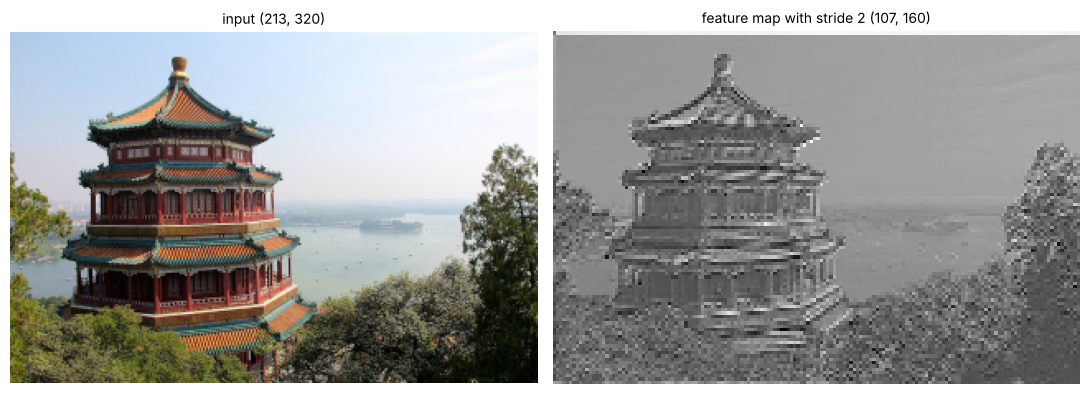

In [20]:
strided = nn.Conv2d(3, 4, kernel_size=3, stride=2, padding=1)
with torch.no_grad():
    out = strided(images)

print("input :", tuple(images.shape))
print("output:", tuple(out.shape))
show_images([images[0].permute(1, 2, 0), out[0, 0]],
            [f"input {tuple(images.shape[2:])}", f"feature map with stride 2 {tuple(out.shape[2:])}"], figsize=(11, 4))

Even with padding, a stride of 2 halves both spatial dimensions.

> **PyTorch detail.** `padding="same"` only works with `stride=1`. With a larger stride, pass the integer yourself (`padding=k//2`), as above.

Other arguments of `nn.Conv2d` worth knowing, which you will meet in later architectures:

- **`dilation`**: spreads the kernel taps apart, enlarging the receptive field without adding parameters (used in segmentation).
- **`groups`**: splits the channels into independent groups; `groups=in_channels` gives the *depthwise* convolution of MobileNet.
- **`kernel_size=1`**: a 1×1 convolution mixes channels at each pixel without looking at neighbours; it is used to change the number of channels cheaply.

Recommended reading on convolution arithmetic: [Convolution arithmetic tutorial](https://theano-pymc.readthedocs.io/en/latest/tutorial/conv_arithmetic.html) and [Convolutional neural networks (Jeremy Jordan)](https://www.jeremyjordan.me/convolutional-neural-networks/).

## 4. Pooling layers

Strided convolution is one way to downsample. The other, used very often, is **pooling**.

A pooling layer also slides a window over its input, so its neurons have a receptive field, a kernel size, a stride and a padding like a convolution. The difference is that the window has **no weights**: it applies a fixed aggregation function.

- **Max pooling** keeps the largest value of each window.
- **Average pooling** keeps the mean of each window.

Two more properties:

- Pooling works on **each channel independently**: it reduces height and width but never changes the number of channels.
- It has **zero learnable parameters**.

A numeric example with the usual setting, a 2×2 window with stride 2:

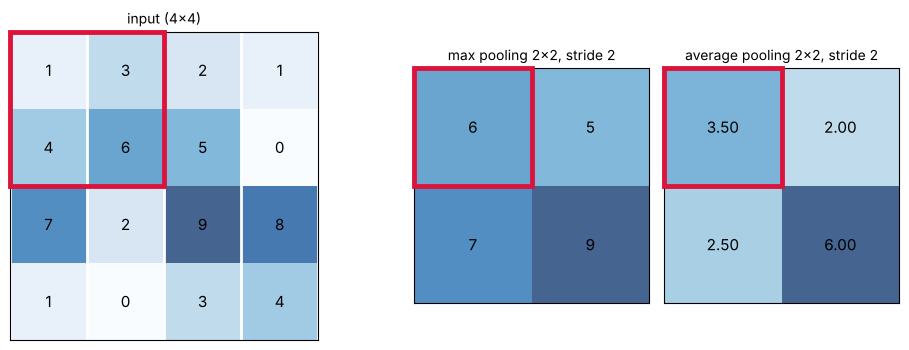

In [21]:
A = torch.tensor([[1., 3., 2., 1.],
                  [4., 6., 5., 0.],
                  [7., 2., 9., 8.],
                  [1., 0., 3., 4.]])

max_out = F.max_pool2d(A[None, None], kernel_size=2)[0, 0]
avg_out = F.avg_pool2d(A[None, None], kernel_size=2)[0, 0]

fig, axes = plt.subplots(1, 3, figsize=(10, 3.6), gridspec_kw={"width_ratios": [4, 2, 2]})
show_matrix(axes[0], A, "input (4x4)", highlight=(0, 0, 2, 2))
show_matrix(axes[1], max_out, "max pooling 2x2, stride 2", highlight=(0, 0, 1, 1))
show_matrix(axes[2], avg_out, "average pooling 2x2, stride 2", highlight=(0, 0, 1, 1), fmt="{:.2f}")
plt.tight_layout()
plt.show()

In PyTorch the layers are [`nn.MaxPool2d`](https://pytorch.org/docs/stable/generated/torch.nn.MaxPool2d.html) and [`nn.AvgPool2d`](https://pytorch.org/docs/stable/generated/torch.nn.AvgPool2d.html). `kernel_size` is mandatory, and **`stride` defaults to `kernel_size`**, so `nn.MaxPool2d(2)` is the usual "halve the resolution" layer (equivalent to the Keras default `MaxPool2D()`).

In [22]:
max_pool = nn.MaxPool2d(kernel_size=2)                 # stride=2, padding=0 by default
avg_pool = nn.AvgPool2d(kernel_size=2)

print("input      :", tuple(images.shape))
print("max pooling:", tuple(max_pool(images).shape))
print("avg pooling:", tuple(avg_pool(images).shape))
print("learnable parameters:", sum(p.numel() for p in max_pool.parameters()))

input      : (2, 3, 213, 320)
max pooling: (2, 3, 106, 160)
avg pooling: (2, 3, 106, 160)
learnable parameters: 0


Height and width are halved, and the 3 channels are untouched. To see what each one does, we apply a stronger 8×8 pooling directly to the photo:

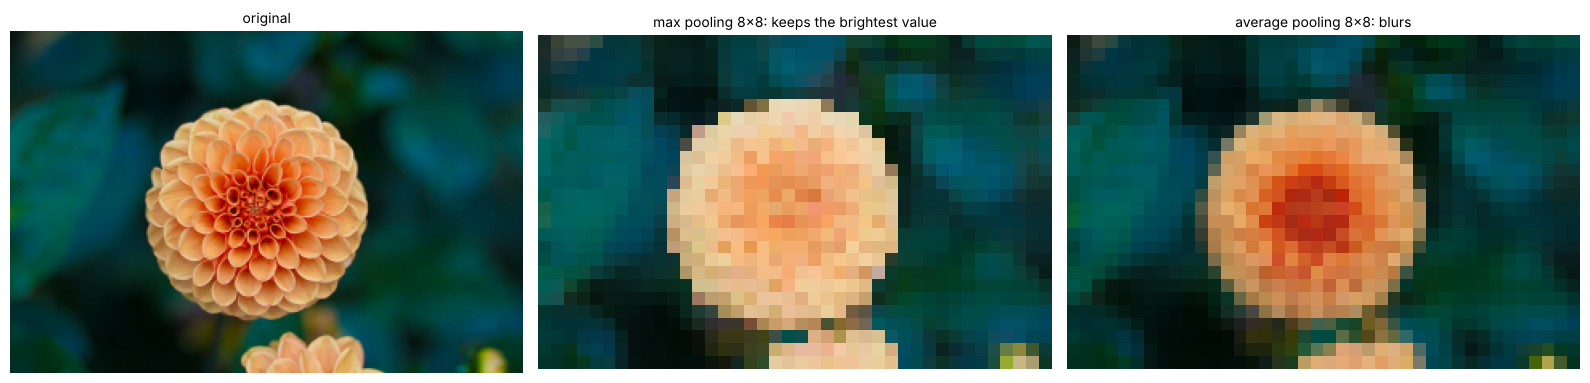

In [23]:
show_images([images[1].permute(1, 2, 0),
             F.max_pool2d(images, 8)[1].permute(1, 2, 0),
             F.avg_pool2d(images, 8)[1].permute(1, 2, 0)],
            ["original", "max pooling 8x8: keeps the brightest value", "average pooling 8x8: blurs"], figsize=(16, 4))

Max pooling on a raw photo just makes bright areas grow, which is not very meaningful. Pooling is designed for **feature maps**, where a high value means "the pattern of this filter was found here". Max pooling then answers "was the pattern found *anywhere* in this window?", keeping the strongest detections and discarding the weak ones. This is why max pooling is the more common choice inside the network, while average pooling is mostly used at the very end (global average pooling, below).

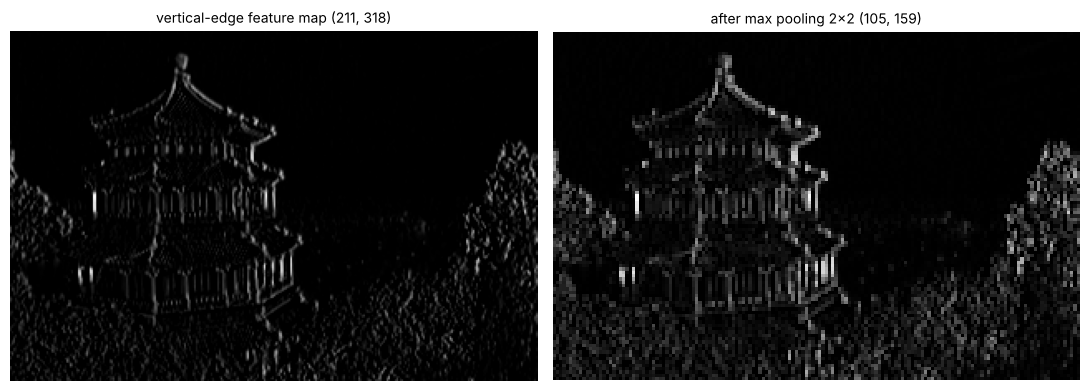

In [24]:
with torch.no_grad():
    edge_map = F.relu(sobel_layer(gray[0][None, None]))          # conv + ReLU
    pooled = F.max_pool2d(edge_map, 2)

show_images([edge_map[0, 0], pooled[0, 0]],
            [f"vertical-edge feature map {tuple(edge_map.shape[2:])}", f"after max pooling 2x2 {tuple(pooled.shape[2:])}"],
            figsize=(11, 4))

With a quarter of the values, the edge structure is preserved.

### 4.1 Why do we downsample?

**1. Computational cost.** Halving height and width divides the number of activations, and the work of every following layer, by 4.

**2. Larger receptive fields.** After a 2×2 pooling, each pixel summarises a 2×2 region, so a 3×3 kernel in the next layer covers a 6×6 region of the layer before the pooling. Downsampling is what lets deep layers "see" large objects with small kernels. We can compute the receptive field of a stack of layers with a simple recurrence: for each layer with kernel $k$ and stride $s$,

$$
r \leftarrow r + (k - 1)\cdot j, \qquad j \leftarrow j \cdot s
$$

starting from $r = 1$, $j = 1$, where $j$ (the "jump") is the distance in input pixels between two neighbouring neurons of the current layer.

In [25]:
def receptive_field(layers):
    # layers: list of (name, kernel_size, stride). Prints the receptive field after each layer.
    r, j = 1, 1
    for name, k, s in layers:
        r = r + (k - 1) * j
        j = j * s
        print(f"  {name:12s} -> receptive field {r:3d} x {r:<3d} (jump {j})")
    return r


print("Four 3x3 convolutions, no pooling:")
receptive_field([("conv 3x3", 3, 1)] * 4)

print("\nSame four convolutions with 2x2 pooling after the 2nd and the 4th:")
receptive_field([("conv 3x3", 3, 1), ("conv 3x3", 3, 1), ("maxpool 2x2", 2, 2),
                 ("conv 3x3", 3, 1), ("conv 3x3", 3, 1), ("maxpool 2x2", 2, 2)]);

Four 3x3 convolutions, no pooling:
  conv 3x3     -> receptive field   3 x 3   (jump 1)
  conv 3x3     -> receptive field   5 x 5   (jump 1)
  conv 3x3     -> receptive field   7 x 7   (jump 1)
  conv 3x3     -> receptive field   9 x 9   (jump 1)

Same four convolutions with 2x2 pooling after the 2nd and the 4th:
  conv 3x3     -> receptive field   3 x 3   (jump 1)
  conv 3x3     -> receptive field   5 x 5   (jump 1)
  maxpool 2x2  -> receptive field   6 x 6   (jump 2)
  conv 3x3     -> receptive field  10 x 10  (jump 2)
  conv 3x3     -> receptive field  14 x 14  (jump 2)
  maxpool 2x2  -> receptive field  16 x 16  (jump 4)


**3. Invariance to small translations.** Max pooling only reports the largest value in each window, not *where* inside the window it was. If a feature moves but stays in the same window, the output does not change at all.

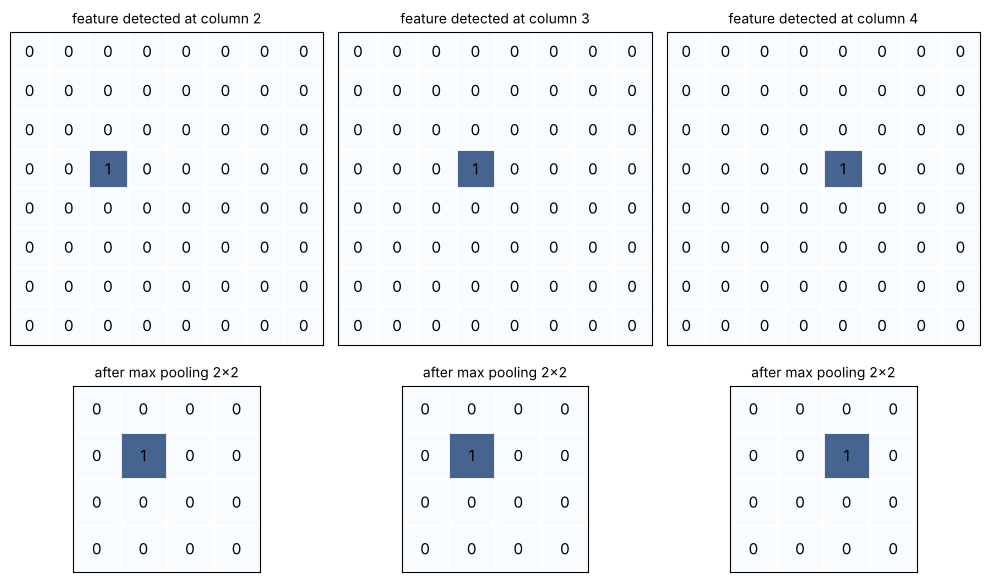

In [26]:
def feature_at(col, size=8):
    # An 8x8 feature map with a single detection in row 3 at the given column.
    fm = torch.zeros(1, 1, size, size)
    fm[0, 0, 3, col] = 1.0
    return fm


fig, axes = plt.subplots(2, 3, figsize=(10, 6), gridspec_kw={"height_ratios": [2, 1]})
for ax_col, col in enumerate([2, 3, 4]):
    fm = feature_at(col)
    show_matrix(axes[0, ax_col], fm[0, 0], f"feature detected at column {col}")
    show_matrix(axes[1, ax_col], F.max_pool2d(fm, 2)[0, 0], "after max pooling 2x2")
plt.tight_layout()
plt.show()

Moving the feature from column 2 to column 3 leaves the pooled output identical (both columns fall in the same window). Moving it to column 4 crosses a window boundary and the output changes, but only by one cell instead of two. So the invariance is **approximate and local**: it holds for shifts smaller than the pooling window, and it accumulates over successive pooling layers.

Average pooling gives a similar but weaker effect. Max pooling is also a non-linear operation, whereas average pooling is linear.

### 4.2 Invariance or equivariance: which one do we want?

It depends on the task.

- **Classification** ("is there a cat in this image?") wants **invariance**: the answer should not depend on where the cat is. Pooling helps by gradually discarding position.
- **Segmentation and detection** ("which pixels are the cat?") want **equivariance**: if the cat moves 10 pixels to the right, the predicted mask must move 10 pixels to the right. Discarding position is harmful here, which is why segmentation architectures (U-Net, for instance) add skip connections to recover the spatial detail lost by downsampling.

Pooling does not make a network fully translation-invariant. Robustness to large shifts mostly comes from the data, which is one reason **data augmentation** (random shifts, crops, flips) is standard practice.

**Pooling or strided convolution?** Both downsample. Pooling has no parameters and gives the invariance above; a strided convolution *learns* how to downsample. Classic networks (LeNet, AlexNet, VGG) use max pooling, while many modern ones (ResNet in most of its stages, and most generative models) use strided convolutions.

### 4.3 Global average pooling

One special pooling layer is used at the *end* of a network: **global average pooling** (GAP) averages each feature map completely, turning a tensor $(N, C, H, W)$ into $(N, C)$, one number per channel. In PyTorch it is `nn.AdaptiveAvgPool2d(1)`, where you specify the *output* size and the layer picks the window.

In [27]:
fmaps = torch.randn(8, 64, 7, 7)                       # e.g. the output of the last conv block

gap = nn.AdaptiveAvgPool2d(1)
print("feature maps        :", tuple(fmaps.shape))
print("after GAP           :", tuple(gap(fmaps).shape))
print("after GAP + flatten :", tuple(gap(fmaps).flatten(1).shape))
print("equal to mean over H and W:", torch.allclose(gap(fmaps).flatten(1), fmaps.mean(dim=(2, 3)), atol=1e-6))

feature maps        : (8, 64, 7, 7)
after GAP           : (8, 64, 1, 1)
after GAP + flatten : (8, 64)
equal to mean over H and W: True


GAP replaces the flatten step (next section) with a far smaller vector, removes the dependence on the input resolution, and is used in almost every modern architecture (ResNet, EfficientNet, ...). We will compare both options in Part 5.

Further reading on pooling, invariance and equivariance: [Deep Learning book, chapter 9](https://www.deeplearningbook.org/contents/convnets.html), [Deep Learning – Equivariance and Invariance](https://www.doc.ic.ac.uk/~bkainz/teaching/DL/notes/equivariance.pdf), [Pooling vs. stride for downsampling](https://stats.stackexchange.com/questions/387482/pooling-vs-stride-for-downsampling).

## 5. Dense layers: from feature maps to a decision

Convolution and pooling blocks, stacked several times, form the **feature extractor**: they turn an image into a small set of feature maps describing what it contains. To classify, we need a second part that turns those features into one score per class: the **classifier head**, made of our old friends the dense (fully connected) layers, `nn.Linear` in PyTorch.

**Flatten.** A dense layer expects a vector per example, but the feature extractor outputs a 3-D block $(C, H, W)$ per example. `nn.Flatten()` reshapes $(N, C, H, W)$ into $(N, C \cdot H \cdot W)$, keeping the batch dimension. It has no parameters and does not change any value.

In [28]:
fmaps = torch.randn(8, 32, 7, 7)

flat = nn.Flatten()(fmaps)
print("feature maps:", tuple(fmaps.shape))
print("flattened   :", tuple(flat.shape), "  (32 * 7 * 7 = 1568)")

dense = nn.Linear(in_features=1568, out_features=10)
print("class scores:", tuple(dense(flat).shape))

feature maps: (8, 32, 7, 7)
flattened   : (8, 1568)   (32 * 7 * 7 = 1568)
class scores: (8, 10)


**The output layer.** Its size and the loss depend on the problem:

| Problem | Output layer | Turn scores into probabilities with | Loss in PyTorch |
|---|---|---|---|
| Binary | 1 neuron | sigmoid | `nn.BCEWithLogitsLoss` |
| Multi-class ($K$ classes) | $K$ neurons | softmax | `nn.CrossEntropyLoss` |

Three details that are often misunderstood:

- The raw outputs of the last layer are called **logits**: unbounded real numbers.
- **Sigmoid** outputs a probability *between* 0 and 1 (not "either 0 or 1"). The class is decided afterwards by thresholding, typically at 0.5.
- **Softmax** is applied to the whole vector of $K$ logits at once (not neuron by neuron): $\mathrm{softmax}(z)_i = e^{z_i} / \sum_j e^{z_j}$. The outputs are positive and sum to 1. The predicted class is the `argmax`.

> **PyTorch detail (a classic bug when coming from Keras).** `nn.CrossEntropyLoss` applies `log_softmax` internally, so the model must output **logits**: do **not** put a softmax as the last layer. In Keras the usual pattern is the opposite (`Dense(10, activation="softmax")` with `sparse_categorical_crossentropy`). Adding a softmax before `CrossEntropyLoss` does not raise an error; the model just trains worse.

In [29]:
classes3 = ["car", "computer", "dog"]
logits = torch.tensor([[1.2, 3.1, 0.3]])              # raw scores for one example
probs = F.softmax(logits, dim=1)

for name, z, p in zip(classes3, logits[0], probs[0]):
    print(f"{name:9s} logit = {z.item():4.1f}   probability = {p.item():.2f}")
print("sum of probabilities:", round(probs.sum().item(), 4))
print("prediction:", classes3[probs.argmax(dim=1).item()])

target = torch.tensor([1])                            # the true class is "computer"
print("\nCrossEntropyLoss(logits)       :", round(nn.CrossEntropyLoss()(logits, target).item(), 4))
print("-log(probability of true class):", round(-probs[0, 1].log().item(), 4))

car       logit =  1.2   probability = 0.12
computer  logit =  3.1   probability = 0.83
dog       logit =  0.3   probability = 0.05
sum of probabilities: 1.0
prediction: computer

CrossEntropyLoss(logits)       : 0.1909
-log(probability of true class): 0.1909


**Flatten or global average pooling?** The size of the first dense layer depends on how many values come out of the feature extractor. With flatten, that number is $C \cdot H \cdot W$, and this single layer often holds most of the parameters of the whole network:

In [30]:
head_flatten = nn.Sequential(nn.Flatten(), nn.Linear(32 * 7 * 7, 64), nn.ReLU(), nn.Linear(64, 10))
head_gap = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(32, 10))

count = lambda m: sum(p.numel() for p in m.parameters())
print(f"flatten -> Linear(1568, 64) -> Linear(64, 10): {count(head_flatten):>7,} parameters")
print(f"GAP     -> Linear(32, 10)                    : {count(head_gap):>7,} parameters")

flatten -> Linear(1568, 64) -> Linear(64, 10): 101,066 parameters
GAP     -> Linear(32, 10)                    :     330 parameters


## 6. MLP vs. CNN

Why not use only dense layers on the flattened image, as in a multilayer perceptron (MLP)?

**1. Number of parameters.** A dense layer connects every input to every output, so its size grows with the *resolution* of the image. Take the small MLP of the classic illustration: 784 inputs (a 28×28 image), two hidden layers of 16 neurons and 10 outputs.

In [31]:
small_mlp = nn.Sequential(nn.Flatten(), nn.Linear(784, 16), nn.ReLU(), nn.Linear(16, 16), nn.ReLU(), nn.Linear(16, 10))

for name, layer in [("hidden 1", small_mlp[1]), ("hidden 2", small_mlp[3]), ("output", small_mlp[5])]:
    print(f"{name:8s}: {layer.in_features:>3} * {layer.out_features:>2} + {layer.out_features:>2} = {count(layer):>6,}")
print(f"total   : {count(small_mlp):,}")

hidden 1: 784 * 16 + 16 = 12,560
hidden 2:  16 * 16 + 16 =    272
output  :  16 * 10 + 10 =    170
total   : 13,002


In [32]:
print(f"{'input image':>16} | {'Linear(pixels -> 64 units)':>27} | {'Conv2d(3 -> 64, 3x3)':>21}")
for side in [28, 224, 1024]:
    dense_params = (side * side * 3 + 1) * 64
    conv_params = (3 * 3 * 3 + 1) * 64
    print(f"{f'{side} x {side} x 3':>16} | {dense_params:>27,} | {conv_params:>21,}")

     input image |  Linear(pixels -> 64 units) |  Conv2d(3 -> 64, 3x3)
     28 x 28 x 3 |                     150,592 |                 1,792
   224 x 224 x 3 |                   9,633,856 |                 1,792
 1024 x 1024 x 3 |                 201,326,656 |                 1,792


A first dense layer of only 64 units on a 1024×1024 colour image needs about 200 million parameters. The convolutional layer needs 1,792 whatever the resolution.

**2. Local versus global structure.** After flattening, an MLP has no notion of which pixels are neighbours: you could apply the same random permutation to the pixels of every image and it would train exactly as well. A CNN exploits the 2-D grid: it detects local patterns and combines them hierarchically.

**3. Translation.** A CNN reuses a learned pattern at every position. An MLP that learned a pattern at one position knows nothing about it at another.

Let's check points 1 and 3 experimentally by training both on **Fashion-MNIST**: 70,000 grayscale images of 28×28 pixels in 10 clothing classes.

### 6.1 Data

train: 60000 | validation: 10000
one batch: (128, 1, 28, 28) torch.float32 | labels: (128,) torch.int64


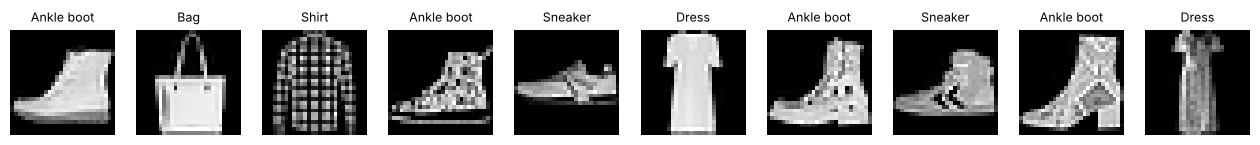

In [33]:
# ToTensor: uint8 (H, W) in [0, 255] -> float (1, H, W) in [0, 1]
# Normalize: subtract the mean and divide by the std of the training set
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=(0.2860,), std=(0.3530,)),
])

train_set = datasets.FashionMNIST("data", train=True, download=True, transform=transform)
valid_set = datasets.FashionMNIST("data", train=False, download=True, transform=transform)

train_loader = DataLoader(train_set, batch_size=128, shuffle=True)
valid_loader = DataLoader(valid_set, batch_size=512)

class_names = train_set.classes
xb, yb = next(iter(train_loader))
print("train:", len(train_set), "| validation:", len(valid_set))
print("one batch:", tuple(xb.shape), xb.dtype, "| labels:", tuple(yb.shape), yb.dtype)

fig, axes = plt.subplots(1, 10, figsize=(16, 2.2))
for ax, img, label in zip(axes, xb, yb):
    ax.imshow(img[0], cmap="gray")
    ax.set_title(class_names[label], fontsize=9)
    ax.axis("off")
plt.show()

(We follow the original notebook and use the official test split as validation data. In a real project, keep a third, untouched split for the final evaluation.)

### 6.2 The two models

The CNN follows the pattern of the introduction: two convolutional blocks, each one `[Conv → BatchNorm → ReLU] × 2 → MaxPool`, followed by flatten and dense layers.

In [34]:
class MLP(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28 * 28, 256), nn.ReLU(),
            nn.Linear(256, 128), nn.ReLU(),
            nn.Linear(128, num_classes),
        )

    def forward(self, x):
        return self.net(x)


def conv_block(in_ch, out_ch):
    # [Conv 3x3 -> BatchNorm -> ReLU] x 2 -> MaxPool: height and width are halved.
    return nn.Sequential(
        nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1, bias=False),
        nn.BatchNorm2d(out_ch),
        nn.ReLU(),
        nn.Conv2d(out_ch, out_ch, kernel_size=3, padding=1, bias=False),
        nn.BatchNorm2d(out_ch),
        nn.ReLU(),
        nn.MaxPool2d(2),
    )


class CNN(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        self.features = nn.Sequential(             # feature extractor
            conv_block(1, 16),                     # (N,  1, 28, 28) -> (N, 16, 14, 14)
            conv_block(16, 32),                    # (N, 16, 14, 14) -> (N, 32,  7,  7)
        )
        self.classifier = nn.Sequential(           # classifier head
            nn.Flatten(),                          # (N, 32, 7, 7) -> (N, 1568)
            nn.Linear(32 * 7 * 7, 64), nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(64, num_classes),            # logits: no softmax here
        )

    def forward(self, x):
        return self.classifier(self.features(x))

Design choices, and how they differ from the Keras model of the original notebook:

- **3×3 kernels instead of 7×7.** Two stacked 3×3 convolutions have the same receptive field as one 5×5 (and three as one 7×7), with fewer parameters ($2 \cdot 9 = 18$ versus $25$ weights per channel pair) and an extra non-linearity. This is the main lesson of VGG and the reason 3×3 is the default. A 7×7 kernel on a 7×7 feature map, as in the original, spans the entire map.
- **Conv → BatchNorm → ReLU.** Batch normalisation after each convolution stabilises and speeds up training. The convolution then needs no bias (`bias=False`), because BatchNorm has its own shift parameter.
- **Normalised inputs** in the data pipeline, instead of a BatchNorm layer applied to the raw 0–255 pixels.
- **No softmax** in the model, because `CrossEntropyLoss` expects logits.
- **`padding=1`** ("same") so only the pooling layers change the spatial size, which keeps the shape arithmetic simple.

It is good practice to follow the shapes through the network and count the parameters per layer:

In [35]:
def summarize(model, input_shape=(1, 1, 28, 28)):
    x = torch.zeros(input_shape)
    layers = [m for m in model.modules() if len(list(m.children())) == 0]       # leaf layers, in order
    print(f"{'layer':<14}{'output shape':<22}{'parameters':>11}")
    print(f"{'input':<14}{str(tuple(x.shape)):<22}{'':>11}")
    model.eval()
    with torch.no_grad():
        for layer in layers:
            x = layer(x)
            print(f"{type(layer).__name__:<14}{str(tuple(x.shape)):<22}{count(layer):>11,}")
    print(f"{'total':<14}{'':<22}{count(model):>11,}")


summarize(CNN())
print(f"\nMLP total: {count(MLP()):,} parameters")

layer         output shape           parameters
input         (1, 1, 28, 28)                   
Conv2d        (1, 16, 28, 28)               144
BatchNorm2d   (1, 16, 28, 28)                32
ReLU          (1, 16, 28, 28)                 0
Conv2d        (1, 16, 28, 28)             2,304
BatchNorm2d   (1, 16, 28, 28)                32
ReLU          (1, 16, 28, 28)                 0
MaxPool2d     (1, 16, 14, 14)                 0
Conv2d        (1, 32, 14, 14)             4,608
BatchNorm2d   (1, 32, 14, 14)                64
ReLU          (1, 32, 14, 14)                 0
Conv2d        (1, 32, 14, 14)             9,216
BatchNorm2d   (1, 32, 14, 14)                64
ReLU          (1, 32, 14, 14)                 0
MaxPool2d     (1, 32, 7, 7)                   0
Flatten       (1, 1568)                       0
Linear        (1, 64)                   100,416
ReLU          (1, 64)                         0
Dropout       (1, 64)                         0
Linear        (1, 10)                   

Observe that the first dense layer alone holds most of the CNN's parameters, while the four convolutional layers together hold far fewer. The CNN also has fewer parameters than the MLP.

### 6.3 Training loop

Keras hides the training loop behind `model.fit()`. In PyTorch we write it, which takes a few more lines but shows every step. The pieces are always the same:

1. `optimizer.zero_grad()` – clear the gradients of the previous step.
2. `loss = criterion(model(x), y)` – forward pass and loss.
3. `loss.backward()` – backpropagation.
4. `optimizer.step()` – update the weights.

Two switches matter: `model.train()` / `model.eval()` change the behaviour of **Dropout** (active only in training) and **BatchNorm** (batch statistics in training, running averages in evaluation), and `torch.no_grad()` disables gradient tracking during evaluation.

In [36]:
def run_epoch(model, loader, criterion, optimizer=None, shift=0):
    # One pass over the data. Trains if an optimizer is given, otherwise only evaluates.
    # shift > 0 translates every image that many pixels to the right (used later).
    training = optimizer is not None
    model.train() if training else model.eval()
    total_loss, correct, seen = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            if shift:
                x = torch.roll(x, shifts=shift, dims=3)
            logits = model(x)
            loss = criterion(logits, y)
            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * len(y)
            correct += (logits.argmax(dim=1) == y).sum().item()
            seen += len(y)
    return total_loss / seen, correct / seen


def fit(model, epochs, lr=1e-3):
    model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    history = {"train_loss": [], "train_acc": [], "valid_loss": [], "valid_acc": []}
    for epoch in range(1, epochs + 1):
        t0 = time.perf_counter()
        train_loss, train_acc = run_epoch(model, train_loader, criterion, optimizer)
        valid_loss, valid_acc = run_epoch(model, valid_loader, criterion)
        for key, value in zip(history, [train_loss, train_acc, valid_loss, valid_acc]):
            history[key].append(value)
        print(f"epoch {epoch:2d}/{epochs} | train loss {train_loss:.3f} acc {train_acc:.3f} | "
              f"valid loss {valid_loss:.3f} acc {valid_acc:.3f} | {time.perf_counter() - t0:.0f}s")
    return history

In [37]:
EPOCHS = 5

torch.manual_seed(0)
print("MLP")
mlp = MLP()
mlp_history = fit(mlp, EPOCHS)

MLP


epoch  1/5 | train loss 0.489 acc 0.824 | valid loss 0.419 acc 0.847 | 8s


epoch  2/5 | train loss 0.351 acc 0.871 | valid loss 0.357 acc 0.871 | 8s


epoch  3/5 | train loss 0.312 acc 0.883 | valid loss 0.354 acc 0.872 | 8s


epoch  4/5 | train loss 0.285 acc 0.894 | valid loss 0.348 acc 0.873 | 8s


epoch  5/5 | train loss 0.267 acc 0.900 | valid loss 0.343 acc 0.877 | 8s


In [38]:
torch.manual_seed(0)
print("CNN")
cnn = CNN()
cnn_history = fit(cnn, EPOCHS)

CNN


epoch  1/5 | train loss 0.461 acc 0.834 | valid loss 0.309 acc 0.883 | 35s


epoch  2/5 | train loss 0.298 acc 0.892 | valid loss 0.277 acc 0.898 | 30s


epoch  3/5 | train loss 0.259 acc 0.907 | valid loss 0.242 acc 0.911 | 30s


epoch  4/5 | train loss 0.234 acc 0.915 | valid loss 0.245 acc 0.910 | 31s


epoch  5/5 | train loss 0.218 acc 0.921 | valid loss 0.248 acc 0.912 | 30s


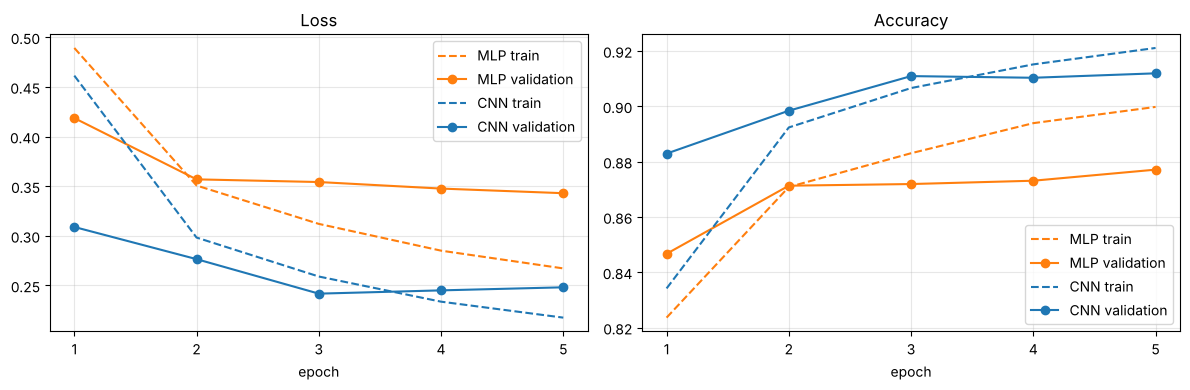

MLP: 235,146 parameters | final validation accuracy 0.877
CNN: 117,530 parameters | final validation accuracy 0.912


In [39]:
epochs_axis = range(1, EPOCHS + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, hist, color in [("MLP", mlp_history, "tab:orange"), ("CNN", cnn_history, "tab:blue")]:
    axes[0].plot(epochs_axis, hist["train_loss"], "--", color=color, label=f"{name} train")
    axes[0].plot(epochs_axis, hist["valid_loss"], "-o", color=color, label=f"{name} validation")
    axes[1].plot(epochs_axis, hist["train_acc"], "--", color=color, label=f"{name} train")
    axes[1].plot(epochs_axis, hist["valid_acc"], "-o", color=color, label=f"{name} validation")
axes[0].set(title="Loss", xlabel="epoch", xticks=list(epochs_axis))
axes[1].set(title="Accuracy", xlabel="epoch", xticks=list(epochs_axis))
for ax in axes:
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

print(f"MLP: {count(mlp):>7,} parameters | final validation accuracy {mlp_history['valid_acc'][-1]:.3f}")
print(f"CNN: {count(cnn):>7,} parameters | final validation accuracy {cnn_history['valid_acc'][-1]:.3f}")

With about half the parameters, the CNN reaches a clearly higher validation accuracy than the MLP (roughly 91% versus 88% in our run; exact numbers vary a little with the hardware and the seed). The MLP's training accuracy keeps rising while its validation accuracy stalls, the usual sign of overfitting. The price of the CNN is computation: each parameter is reused at every position of the image, so an epoch takes longer, which is why CNNs are normally trained on a GPU.

### 6.4 Robustness to translation

Now point 3. We shift every validation image a few pixels to the right and evaluate both models **without retraining**. Neither model saw shifted images during training.

shift (px) |     0 |     1 |     2 |     3 |     4
MLP        | 0.877 | 0.791 | 0.524 | 0.278 | 0.187
CNN        | 0.912 | 0.891 | 0.831 | 0.641 | 0.369


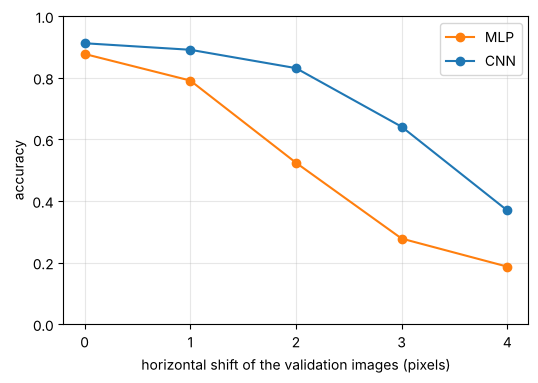

In [40]:
shifts = [0, 1, 2, 3, 4]
criterion = nn.CrossEntropyLoss()
mlp_shift_acc = [run_epoch(mlp, valid_loader, criterion, shift=s)[1] for s in shifts]
cnn_shift_acc = [run_epoch(cnn, valid_loader, criterion, shift=s)[1] for s in shifts]

print("shift (px) | " + " | ".join(f"{s:>5d}" for s in shifts))
print("MLP        | " + " | ".join(f"{a:5.3f}" for a in mlp_shift_acc))
print("CNN        | " + " | ".join(f"{a:5.3f}" for a in cnn_shift_acc))

plt.figure(figsize=(6, 4))
plt.plot(shifts, mlp_shift_acc, "-o", color="tab:orange", label="MLP")
plt.plot(shifts, cnn_shift_acc, "-o", color="tab:blue", label="CNN")
plt.xlabel("horizontal shift of the validation images (pixels)")
plt.ylabel("accuracy")
plt.xticks(shifts)
plt.ylim(0, 1)
plt.grid(alpha=0.3)
plt.legend()
plt.show()

(`torch.roll` wraps the columns that leave on the right back to the left side; in Fashion-MNIST those columns are almost always empty background, so this is a reasonable approximation of a real shift.)

Both models lose accuracy, but the MLP collapses much faster: in our run a 2-pixel shift costs it about 35 points of accuracy and the CNN about 8. For the MLP every pixel is a separate, unrelated input, so a shifted image is a completely new input vector. The CNN's convolutional features simply move with the image (equivariance) and the pooling layers absorb part of the shift.

The CNN is **not** fully invariant either, and it is worth understanding why: the `Flatten` + `Linear` head assigns a different weight to each position of the 7x7 feature maps, so it is itself position-dependent, and every training image was centred. Two standard remedies are global average pooling (exercise 3) and data augmentation with random translations (exercise 4).

### 6.5 What did the CNN learn?

Finally, let's look inside the trained CNN: the 16 kernels of its first layer and the feature maps they produce for one image. Compare them with the hand-designed kernels of Part 1.

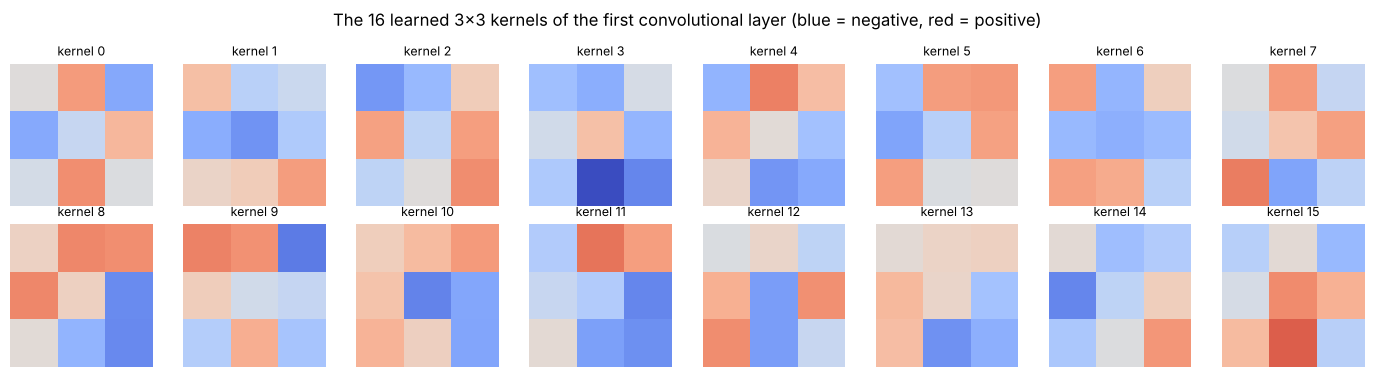

In [41]:
first_conv = cnn.features[0][0]
learned = first_conv.weight.detach().cpu()               # (16, 1, 3, 3)

fig, axes = plt.subplots(2, 8, figsize=(14, 3.8))
vmax = learned.abs().max()
for i, ax in enumerate(axes.flat):
    ax.imshow(learned[i, 0], cmap="coolwarm", vmin=-vmax, vmax=vmax)
    ax.set_title(f"kernel {i}", fontsize=9)
    ax.axis("off")
fig.suptitle("The 16 learned 3x3 kernels of the first convolutional layer (blue = negative, red = positive)")
plt.tight_layout()
plt.show()

true class: Ankle boot | predicted: Ankle boot


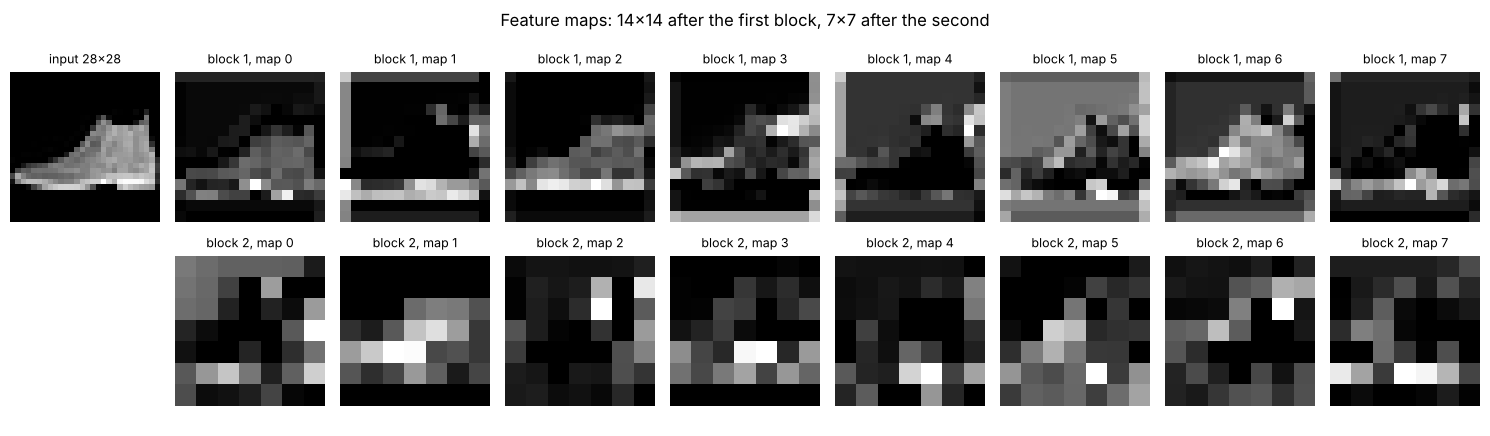

In [42]:
sample, label = valid_set[0]
cnn.eval()
with torch.no_grad():
    block1 = cnn.features[0](sample[None].to(device))    # output of the first block: (1, 16, 14, 14)
    block2 = cnn.features[1](block1)                     # output of the second block: (1, 32, 7, 7)
    prediction = cnn.classifier(block2).argmax(dim=1).item()

print(f"true class: {class_names[label]} | predicted: {class_names[prediction]}")

fig, axes = plt.subplots(2, 9, figsize=(15, 4.4))
for row in axes:
    row[0].axis("off")
axes[0, 0].imshow(sample[0], cmap="gray")
axes[0, 0].set_title("input 28x28", fontsize=9)
for i in range(8):
    axes[0, i + 1].imshow(block1[0, i].cpu(), cmap="gray")
    axes[0, i + 1].set_title(f"block 1, map {i}", fontsize=9)
    axes[0, i + 1].axis("off")
    axes[1, i + 1].imshow(block2[0, i].cpu(), cmap="gray")
    axes[1, i + 1].set_title(f"block 2, map {i}", fontsize=9)
    axes[1, i + 1].axis("off")
fig.suptitle("Feature maps: 14x14 after the first block, 7x7 after the second")
plt.tight_layout()
plt.show()

The first block keeps a recognisable, edge-like picture of the garment at 14×14. After the second block the maps are 7×7, more abstract and more sparse: each one responds to a specific combination of the earlier features, in a rough location. This is the hierarchy of Part 2, and those 32 × 7 × 7 values are what the dense layers use to decide the class.

## Summary

| Concept | Key idea | PyTorch |
|---|---|---|
| Convolution | Slide a kernel and take dot products with each patch (technically cross-correlation) | `F.conv2d` |
| Convolutional layer | Learnable filters; local connectivity + weight sharing; equivariant to translation | `nn.Conv2d(in_ch, out_ch, k)` |
| Parameters | $(k_h k_w C_{in} + 1)\,C_{out}$, independent of the image size | `sum(p.numel() for p in m.parameters())` |
| Padding | Border of zeros to control the output size and use the borders | `padding=0`, `"same"`, `p` |
| Stride | Step of the kernel; $s>1$ downsamples | `stride=s` |
| Output size | $\lfloor (n + 2p - k)/s \rfloor + 1$ | |
| Pooling | Fixed aggregation (max / average), no parameters, per channel | `nn.MaxPool2d`, `nn.AvgPool2d` |
| Global average pooling | One value per feature map | `nn.AdaptiveAvgPool2d(1)` |
| Flatten + dense | Turn feature maps into class scores (logits) | `nn.Flatten`, `nn.Linear` |
| Loss | Takes logits; do not add softmax to the model | `nn.CrossEntropyLoss` |

## Exercises

1. Without running code, compute the output shape and the number of parameters of `nn.Conv2d(64, 128, kernel_size=5, stride=2, padding=2)` for an input of shape `(16, 64, 56, 56)`. Then verify.
2. Replace the two `nn.MaxPool2d(2)` of the CNN by `stride=2` in the second convolution of each block. Compare accuracy, parameters and the translation experiment.
3. Replace the head by global average pooling followed by a single `nn.Linear(32, 10)`. How many parameters does the model have now? How does the accuracy change, and the robustness to shifts?
4. Add data augmentation with `transforms.RandomAffine(degrees=0, translate=(0.15, 0.15))` to the training transform and repeat the translation experiment for both models.
5. Apply the same fixed random permutation to the pixels of every image (training and validation) and retrain both models. Which one is affected, and why?
6. Use `receptive_field` to compute the receptive field of a neuron in the last feature map of our CNN. Does it cover the whole 28×28 image?

## References

Adapted and extended from the TensorFlow notebooks *Fundamentals of Convolutional Neural Networks 1 – Convolution* and *2 – Pooling and Dense Layers*, whose main sources are:

1. Murphy, K. P. (2022). *Probabilistic Machine Learning: An Introduction*. MIT Press.
2. Géron, A. (2022). *Hands-On Machine Learning with Scikit-Learn, Keras, and TensorFlow*. O'Reilly.
3. Chollet, F. (2021). *Deep Learning with Python* (2nd ed.). Manning.
4. Goodfellow, I., Bengio, Y., & Courville, A. (2016). *Deep Learning*, [chapter 9: Convolutional Networks](https://www.deeplearningbook.org/contents/convnets.html). MIT Press.
5. Dumoulin, V., & Visin, F. (2016). *A guide to convolution arithmetic for deep learning* ([tutorial](https://theano-pymc.readthedocs.io/en/latest/tutorial/conv_arithmetic.html)).

Videos: [But what is a convolution?](https://www.youtube.com/watch?v=KuXjwB4LzSA) · [In Depth Explanation: Convolutional Neural Networks From Scratch](https://www.youtube.com/watch?v=jDe5BAsT2-Y) · [How convolutional neural networks work, in depth](https://www.youtube.com/watch?v=JB8T_zN7ZC0)

PyTorch documentation: [`nn.Conv2d`](https://pytorch.org/docs/stable/generated/torch.nn.Conv2d.html) · [`nn.MaxPool2d`](https://pytorch.org/docs/stable/generated/torch.nn.MaxPool2d.html) · [`nn.CrossEntropyLoss`](https://pytorch.org/docs/stable/generated/torch.nn.CrossEntropyLoss.html)